# Testing a research question on real-life data: blood cadmium and blood pressure

**LSABD group project – NHANES 2021-2023 – Part 2** · Group XX

In this notebook, we formulate and test our own research question on the NHANES 2021-2023 data. We follow the
structure of the course notebook *3-real-life-regression*, which we use as a template:

1. Exploring the data
2. Preparing the data
3. Starting simple: a crude linear regression model
4. Adjusting for confounders: multivariable models
5. Effect modification: does the association differ between men and women?
6. Checking the model: assumptions and sensitivity analyses
7. Conclusion

There is one important difference with the template. The template builds a model to **predict** blood pressure, and
judges it by how well it predicts new data (R², MAE on a test set). Here, we want to **test a hypothesis** about one
exposure: is blood cadmium associated with blood pressure, after taking other variables into account? For that, we need
coefficients with confidence intervals and p-values. We therefore fit the linear regression models with
[statsmodels](https://www.statsmodels.org/stable/regression.html) instead of scikit-learn. statsmodels fits exactly the
same linear regression, but also reports the statistics needed to test hypotheses.

**Running this notebook in Google Colab:** upload the file `NHANES_20212023_merged_filtered.csv` with the folder icon on
the left (*Files → Upload*), then choose *Runtime → Run all*.

In [1]:
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set the style for our visualizations
sns.set_style("whitegrid")
sns.set_palette("deep")

## 1. Exploring the data

### Background
The National Health and Nutrition Examination Survey (NHANES) is a program of the US Centers for Disease Control and
Prevention (CDC). Every two years, a representative sample of the US population is interviewed, physically examined, and
asked to provide blood and urine samples. We use the cycle of August 2021 to August 2023.

High blood pressure is one of the most important risk factors for cardiovascular disease. **Cadmium** is a toxic heavy
metal that accumulates in the body over decades (half-life 10-30 years), mainly in the kidneys. In the general
population, the main sources are **tobacco smoke** and food. Cadmium could raise blood pressure through kidney damage,
oxidative stress and damage to the blood vessel wall, but studies in humans are inconsistent. A meta-analysis
(Gallagher & Meliker, 2010) found a positive association between blood cadmium and systolic blood pressure, mainly in
**women**, and pointed out that **smoking** is a key confounder: smokers have more cadmium, and smoking also affects blood
pressure.

### Research question and hypotheses
> Is blood cadmium associated with systolic blood pressure in US adults, independent of age, sex, smoking, BMI, income
> and ethnicity, and does this association differ between men and women?

* **Main effect.** H0: after adjustment, the regression coefficient of log2(blood cadmium) on systolic blood pressure is 0.
  H1: it is different from 0.
* **Interaction.** H0: the association between log2(blood cadmium) and systolic blood pressure is the same in men and
  women (interaction coefficient = 0). H1: it differs between men and women.

### The columns we use
The full table contains several hundred columns. We only need the columns below. The values are exactly as published by
the CDC; click on the data file to see its full documentation:

| Column | Description | Data file |
|---|---|---|
| `SEQN` | Participant ID | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `RIDSTATR` | Interview/examination status (1 = interview only, 2 = interviewed and examined) | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `RIDAGEYR` | Age in years (80 = 80 years or older) | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `RIAGENDR` | Gender (1 = male, 2 = female) | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `RIDRETH3` | Race/Hispanic origin (category code 1-7) | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `RIDEXPRG` | Pregnancy status at exam (1 = pregnant, 2 = not pregnant, 3 = cannot ascertain) | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `INDFMPIR` | Ratio of family income to the poverty threshold (5 = 5 or more) | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `WTMEC2YR`, `SDMVPSU`, `SDMVSTRA` | Exam sample weight, sampling cluster (PSU) and stratum | [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) |
| `BPXOSY1`, `BPXOSY2`, `BPXOSY3` | Systolic blood pressure, readings 1 to 3 (mmHg) | [BPXO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm) |
| `BMXBMI` | Body mass index (kg/m²) | [BMX_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm) |
| `LBXBCD` | Blood cadmium (µg/L) | [PBCD_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PBCD_L.htm) |
| `LBDBCDLC` | Blood cadmium comment code (0 = at or above the detection limit, 1 = below the detection limit) | [PBCD_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PBCD_L.htm) |
| `LBXCOT` | Serum cotinine (ng/mL), a breakdown product of nicotine | [COT_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/COT_L.htm) |

**Question:** What type of variable is the outcome, and which kind of model fits our question?

**Answer:** The outcome, systolic blood pressure in mmHg, is a continuous variable. We therefore use **linear regression**, as in the template. Our goal is different, though: we do not want to predict blood pressure, but to test whether one exposure (cadmium) is associated with it, after adjustment for confounders. We therefore need the coefficient of cadmium with its confidence interval and p-value, which statsmodels provides.

### Loading the data
As in the template, we use the pandas `read_csv()` function to load the table. The file name may end with a different
suffix after downloading; `glob` finds it anyway.

In [2]:
data_file = glob.glob("NHANES_20212023_merged_filtered*.csv")[0]
data = pd.read_csv(data_file, low_memory=False)
data

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DBQ930,DBQ935,DBQ940,DBQ945,ECD070A,ECD070B,ECQ080,ECQ090,WHQ030E,MCQ080E
0,130378,12,2,1,43,NaN,5,6,2.0,NaN,...,2.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,130379,12,2,1,66,NaN,3,3,2.0,NaN,...,2.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2,130380,12,2,2,44,NaN,2,2,1.0,NaN,...,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
3,130381,12,2,2,5,NaN,5,7,1.0,71.0,...,NaN,NaN,NaN,NaN,6.0,9.0,NaN,NaN,3.0,2.0
4,130382,12,2,1,2,NaN,3,3,2.0,34.0,...,NaN,NaN,NaN,NaN,8.0,0.0,NaN,NaN,3.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11928,142306,12,2,1,9,NaN,2,2,1.0,111.0,...,NaN,NaN,NaN,NaN,9999.0,9999.0,1.0,2.0,3.0,2.0
11929,142307,12,2,2,49,NaN,4,4,2.0,NaN,...,2.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
11930,142308,12,2,1,50,NaN,2,2,1.0,NaN,...,2.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
11931,142309,12,2,1,40,NaN,2,2,1.0,NaN,...,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN


**Question:** How many participants (rows) and columns does the table contain? How many columns do we need?

**Answer:** The full table contains 11,933 participants and 486 columns. We only need 17 of them (the columns in the table above), so we keep only those. As in the template, there are many more samples than columns.

### Exploring the columns
As in the template, we decide for each column what its role is. In a hypothesis test, the roles are different from a
prediction model:

1. the **outcome** that we want to explain (the target in the template),
2. the **exposure**: the variable our hypothesis is about,
3. the **confounders**: variables that are related to both the exposure and the outcome, and that we need to adjust for,
4. columns we only use to **select** participants, or for **sensitivity analyses**,
5. the **identifier**, which contains no information.

A **confounder** can create a false association, or hide a real one. Age is an example: cadmium accumulates with age, and
blood pressure also rises with age. Without adjustment, cadmium could look harmful simply because people with more
cadmium are older.

In [3]:
outcome_columns = ["BPXOSY1", "BPXOSY2", "BPXOSY3"]                 # systolic blood pressure readings
exposure_column = "LBXBCD"                                          # blood cadmium
confounder_columns = ["RIDAGEYR", "RIAGENDR", "LBXCOT", "BMXBMI", "INDFMPIR", "RIDRETH3"]
selection_columns = ["RIDSTATR", "RIDEXPRG"]                        # to select the analysis population
sensitivity_columns = ["LBDBCDLC", "WTMEC2YR", "SDMVPSU", "SDMVSTRA"]  # only used in section 6
id_column = "SEQN"

columns = [id_column] + outcome_columns + [exposure_column] + confounder_columns + selection_columns + sensitivity_columns
data = data[columns].copy()
data.shape

(11933, 17)

**Question:** Why is each of the confounders included? Think about how each one is related to cadmium and to blood pressure.

**Answer:** Each confounder is related to both cadmium and blood pressure. **Age:** cadmium accumulates over the years, and blood pressure rises with age. **Sex:** women absorb more cadmium (especially with low iron stores), while men have a higher blood pressure. **Smoking (cotinine):** tobacco smoke is the main source of cadmium, and smoking affects blood pressure. **BMI, income and ethnicity** are related to diet, smoking and blood pressure. The outcome columns are `BPXOSY1-3`, the exposure is `LBXBCD`, `SEQN` is the identifier, `RIDSTATR` and `RIDEXPRG` are only used to select participants, and the weight, cluster, stratum and detection-limit columns are only used in the sensitivity analyses.

Unlike the template, we keep the categorical variable `RIDRETH3` (ethnic background). The template leaves such columns
out because a model would treat the codes 1-7 as measurements. In a statsmodels formula, we can mark a variable as
categorical: statsmodels then creates one indicator (dummy) variable per category, and compares each category with a
reference category. The codes are no longer treated as numbers.

### Exploring the variables
First, let's check the data types with the `dtypes` property, as in the template:

In [4]:
data.dtypes

SEQN          int64
BPXOSY1     float64
BPXOSY2     float64
BPXOSY3     float64
LBXBCD      float64
RIDAGEYR      int64
RIAGENDR      int64
LBXCOT      float64
BMXBMI      float64
INDFMPIR    float64
RIDRETH3      int64
RIDSTATR      int64
RIDEXPRG    float64
LBDBCDLC    float64
WTMEC2YR    float64
SDMVPSU       int64
SDMVSTRA      int64
dtype: object

Next, let's look for special codes and suspicious values with the `describe()` method:

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
SEQN,11933.0,136344.000000,3444.904716,130378.000,133361.000,136344.00000,139327.000000,142310.000000
BPXOSY1,7517.0,119.288546,18.561052,61.000,106.000,117.00000,130.000000,232.000000
BPXOSY2,7505.0,119.079680,18.571271,59.000,106.000,116.00000,129.000000,233.000000
BPXOSY3,7480.0,118.917647,18.495220,50.000,106.000,116.00000,129.000000,232.000000
LBXBCD,7586.0,0.352772,0.470467,0.046,0.128,0.21400,0.383000,8.379000
RIDAGEYR,11933.0,38.317858,25.601990,0.000,13.000,37.00000,62.000000,80.000000
RIAGENDR,11933.0,1.532808,0.498943,1.000,1.000,2.00000,2.000000,2.000000
LBXCOT,7091.0,42.061065,109.691467,0.007,0.007,0.01700,0.356500,1090.000000
BMXBMI,8471.0,27.246665,8.137781,11.100,21.600,26.40000,31.700000,74.800000
INDFMPIR,9892.0,2.708174,1.670119,0.000,1.180,2.50000,4.500000,5.000000


**Question:** Look at the minimum and maximum values. Do these columns contain special codes, such as 7777 for "refused"? Are there other values to be careful with?

**Answer:** None of these columns contains special codes such as 7777 or 9999. As in the template, some values are **top-coded**: an age of 80 means "80 or older" and an income ratio of 5 means "5 or more". `RIDEXPRG` uses the codes 1-3 (1 = pregnant). `RIDRETH3` and `RIAGENDR` are codes, not measurements. Cadmium (`LBXBCD`) has a minimum of 0.046 µg/L: this is the value NHANES fills in for samples below the detection limit (LOD/√2). Cotinine ranges from 0.007 to 1,090 ng/mL, and cadmium from 0.046 to 8.4 µg/L, with medians of only 0.017 and 0.21: both are extremely right-skewed.

Laboratory values such as cadmium are often skewed. Let's look at the distribution of blood cadmium, on the original scale
and on a log2 scale, with the Seaborn `histplot` function:

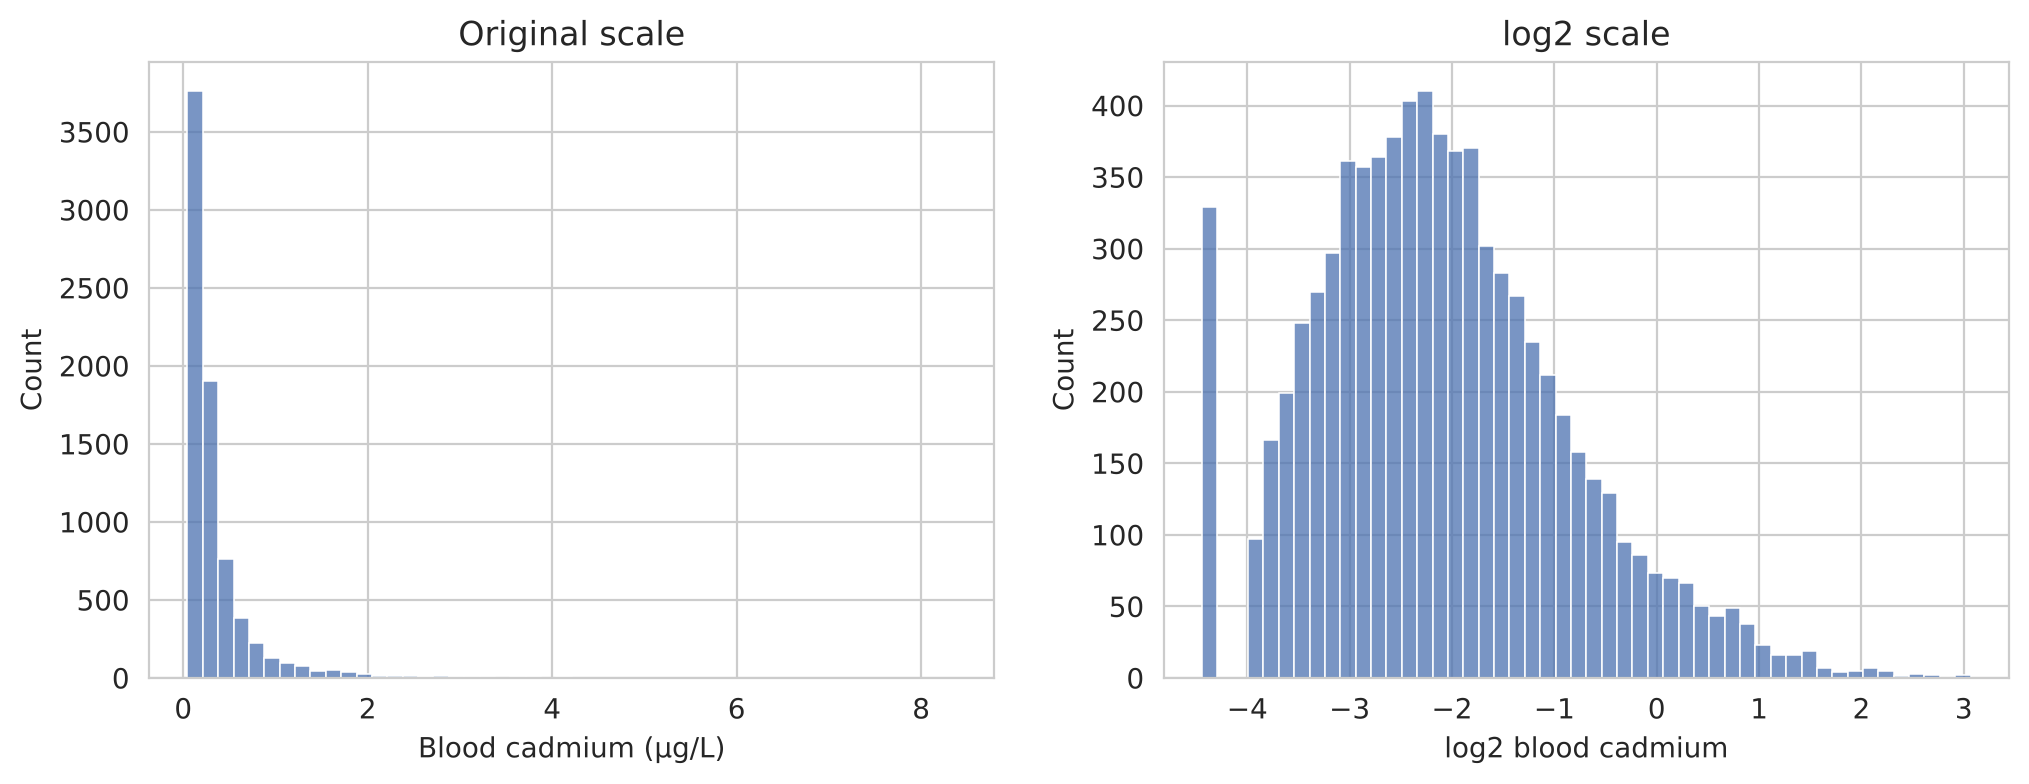

In [6]:
fig, axes = plt.subplots(figsize=(12, 4), ncols=2)
sns.histplot(data=data, x="LBXBCD", bins=50, ax=axes[0])
axes[0].set_xlabel("Blood cadmium (µg/L)")
axes[0].set_title("Original scale")
sns.histplot(x=np.log2(data["LBXBCD"]), bins=50, ax=axes[1])
axes[1].set_xlabel("log2 blood cadmium")
axes[1].set_title("log2 scale")
plt.show()

**Question:** Describe both distributions. Why do we use log2(cadmium) in the models, and how do we interpret its coefficient?

**Answer:** On the original scale, cadmium is strongly right-skewed: most participants have values below 0.4 µg/L, but a small group (mostly smokers) has much higher values, up to 8.4 µg/L. In a model, those few extreme values would dominate the regression line. On the log2 scale, the distribution is much more symmetric. Biologically, exposures are also better compared in ratios: going from 0.1 to 0.2 µg/L is the same relative step as going from 1 to 2 µg/L. With log2, the coefficient is the difference in blood pressure (mmHg) **per doubling** of blood cadmium. The base of the logarithm does not change the p-values; it only changes the scale of the coefficient.

Our dataset has no smoking questionnaire, but it has serum **cotinine**, an objective marker of recent tobacco exposure.
Let's look at its distribution on a log scale:

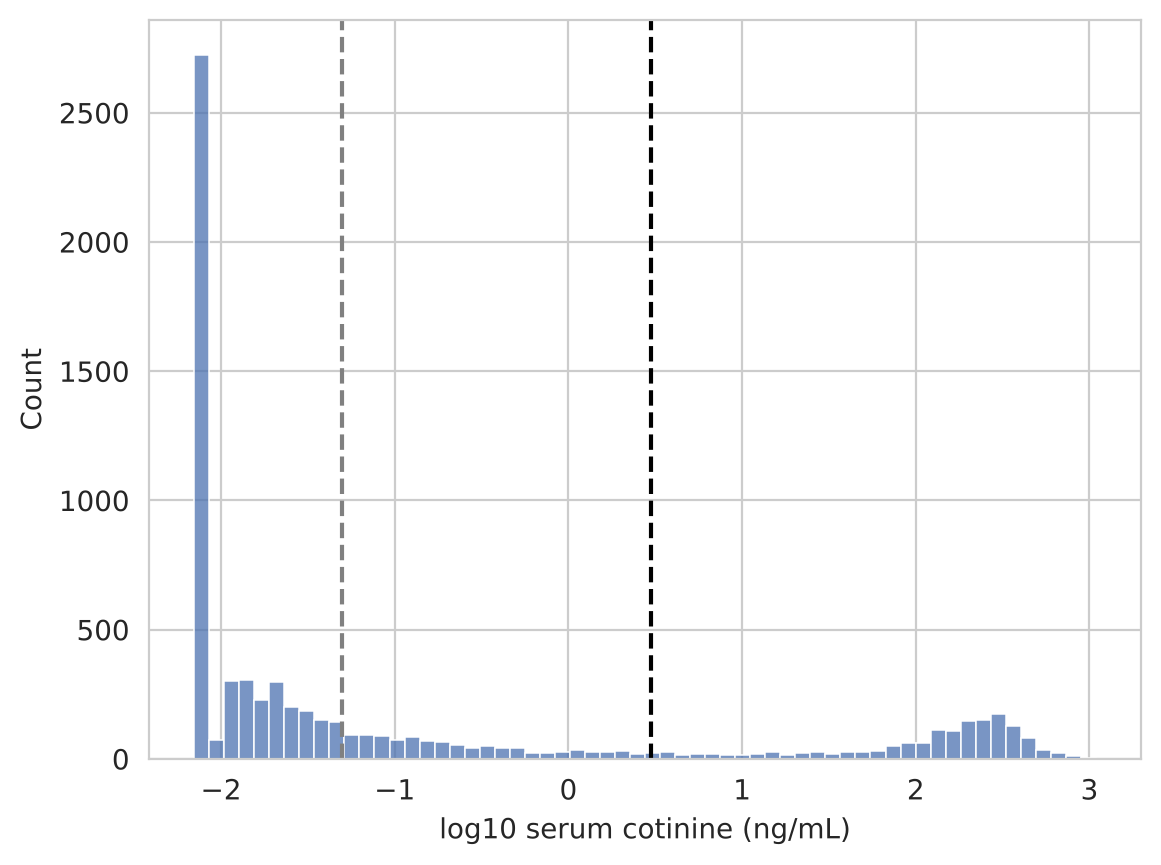

In [7]:
sns.histplot(x=np.log10(data["LBXCOT"]), bins=60)
plt.axvline(np.log10(0.05), color="grey", linestyle="--")
plt.axvline(np.log10(3), color="black", linestyle="--")
plt.xlabel("log10 serum cotinine (ng/mL)")
plt.show()

**Question:** What do you notice about the distribution of cotinine? How can we turn it into a smoking variable?

**Answer:** Cotinine is **bimodal**: one large group with very low values (people not exposed to tobacco smoke), and a second group with high values (smokers). We turn it into three categories: **unexposed** (< 0.05 ng/mL), **secondhand smoke** (0.05 to 3 ng/mL) and **active smoker** (≥ 3 ng/mL, the cut-off of Benowitz et al., 2009). The dashed lines show the two cut-offs.

Now, let's check for missing values with the `isnull()` method:

In [8]:
data.isnull().sum()

SEQN            0
BPXOSY1      4416
BPXOSY2      4428
BPXOSY3      4453
LBXBCD       4347
RIDAGEYR        0
RIAGENDR        0
LBXCOT       4842
BMXBMI       3462
INDFMPIR     2041
RIDRETH3        0
RIDSTATR        0
RIDEXPRG    10430
LBDBCDLC     4347
WTMEC2YR        0
SDMVPSU         0
SDMVSTRA        0
dtype: int64

**Question:** Why are so many values missing?

**Answer:** Most values are missing **by design**. 3,073 participants only did the interview, so they have no blood pressure, body measurements or lab values. Blood pressure and cadmium are not measured in young children. `RIDEXPRG` is only filled in for women of reproductive age, which is why it is missing for 10,430 participants. The survey weights are 0 (not missing) for interview-only participants. We deal with the missing values in the data preparation section.

### Exploring the outcome
As in the template, we use the average of the available blood pressure readings as the outcome. The `mean()` method with
`axis=1` computes the average per row and skips missing readings.

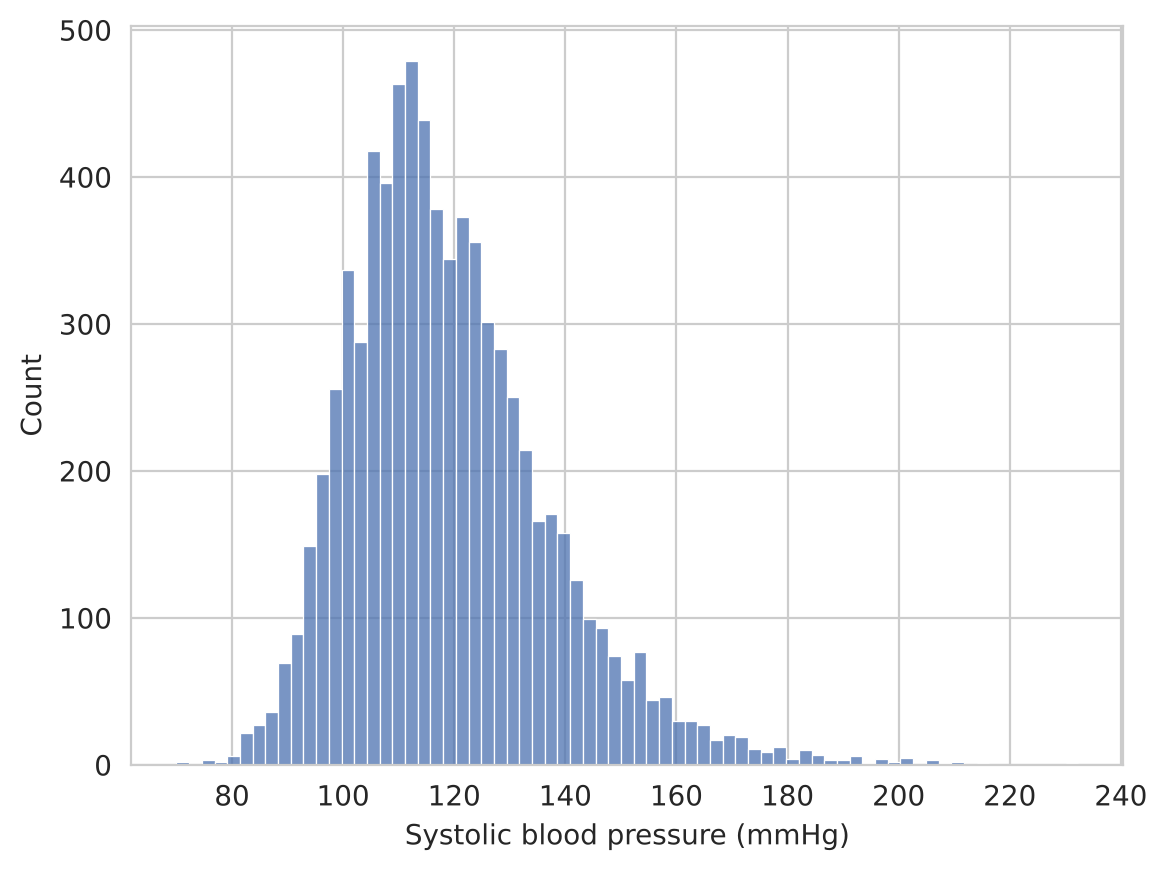

Participants without a blood pressure reading: 4415


count    7518.000000
mean      119.094418
std        18.151729
min        70.000000
25%       106.333333
50%       116.333333
75%       129.000000
max       232.333333
Name: systolic_bp, dtype: float64

In [9]:
data["systolic_bp"] = data[outcome_columns].mean(axis=1)

sns.histplot(data=data, x="systolic_bp")
plt.xlabel("Systolic blood pressure (mmHg)")
plt.show()

print(f"Participants without a blood pressure reading: {data['systolic_bp'].isnull().sum()}")
data["systolic_bp"].describe()

Before using the average, let's check that the three readings agree, with the `corr()` method:

In [10]:
data[outcome_columns].corr().round(2)

,BPXOSY1,BPXOSY2,BPXOSY3
BPXOSY1,1.00,0.94,0.93
BPXOSY2,0.94,1.00,0.94
BPXOSY3,0.93,0.94,1.00


**Question:** Describe the distribution of the outcome. Is it reasonable to average the three readings?

**Answer:** 7,518 participants have at least one blood pressure reading; 4,415 have none (no examination, or young children). Most participants have a systolic blood pressure between about 106 and 129 mmHg (25th and 75th percentiles), with a mean of 119 mmHg. As in the template, the distribution has a long tail to the right, up to 232 mmHg. The three readings are strongly correlated (r = 0.93-0.94), so they measure the same thing: averaging them is reasonable and reduces the measurement error.

## 2. Preparing the data

### Selecting samples
Not every row is a useful sample:

* **Not examined:** participants who only did the interview (`RIDSTATR = 1`) have no blood pressure or lab values.
* **Children and adolescents:** blood pressure follows different norms. We keep adults of **20 years or older**, the usual
  NHANES cut-off for adults (the template used 18).
* **Pregnant women:** pregnancy changes blood pressure and many lab values.
* **Missing outcome, exposure or confounders:** linear regression needs a value for every variable in the model. We keep
  the participants with complete data (**complete-case analysis**).

Let's apply these steps one by one and keep track of how many samples remain:

In [11]:
model_columns = ["systolic_bp", "LBXBCD"] + confounder_columns

print(f"All participants: {len(data)}")

examined = data[data["RIDSTATR"] == 2]
print(f"Examined: {len(examined)}")

adults = examined[examined["RIDAGEYR"] >= 20]
print(f"Adults (20+): {len(adults)}")

analysis_population = adults[adults["RIDEXPRG"] != 1]
print(f"Not pregnant: {len(analysis_population)}")

complete_data = analysis_population.dropna(subset=model_columns).copy()
print(f"Complete data on all model variables: {len(complete_data)}")

All participants: 11933
Examined: 8860
Adults (20+): 6064
Not pregnant: 6023
Complete data on all model variables: 4603


Let's see which variables are responsible for the removed samples:

In [12]:
analysis_population[model_columns].isnull().sum()

systolic_bp    199
LBXBCD         290
RIDAGEYR         0
RIAGENDR         0
LBXCOT         538
BMXBMI          94
INDFMPIR       787
RIDRETH3         0
dtype: int64

Removing samples is only safe if the removed participants are similar to the ones we keep. Let's compare both groups:

In [13]:
analysis_population = analysis_population.assign(included=analysis_population.index.isin(complete_data.index))
analysis_population.groupby("included").agg(
    n=("SEQN", "size"),
    age=("RIDAGEYR", "mean"),
    female=("RIAGENDR", lambda x: (x == 2).mean()),
    systolic_bp=("systolic_bp", "mean"),
    cadmium_median=("LBXBCD", "median"),
).round(3)

,n,age,female,systolic_bp,cadmium_median
included,,,,,
False,1420,53.801,0.554,124.036,0.277
True,4603,54.078,0.547,122.769,0.267


**Question:** Which variable is responsible for most of the removed samples? Could we remove that variable instead? Is complete-case analysis acceptable here?

**Answer:** The income-to-poverty ratio (`INDFMPIR`) is missing for 787 adults, more than any other variable, followed by cotinine (538) and cadmium (290). Unlike in the template, we cannot simply remove income: it is a **confounder**, and leaving it out would make the adjusted estimate less trustworthy. We therefore remove the samples. The comparison shows that the 1,420 removed participants are very similar to the 4,603 we keep in age (54 years), sex (55% women), blood pressure (124 vs 123 mmHg) and cadmium (median 0.28 vs 0.27 µg/L). Complete-case analysis is therefore unlikely to bias the results.

### Creating the analysis variables
We now create the variables in the form we will use them in the models:

* `log2_cd`: log2 of blood cadmium (see section 1);
* `sex`: Male / Female instead of 1 / 2;
* `smoking`: three categories from serum cotinine: **Unexposed** (< 0.05 ng/mL), **Secondhand** (0.05 to 3 ng/mL;
  the lower bound used by the CDC for secondhand smoke) and **Active smoker** (≥ 3 ng/mL; Benowitz et al., 2009);
* `ethnicity`: labels instead of codes.

We store the categorical variables as pandas `Categorical`. The **first category is the reference** to which the other
categories are compared in the models: Male, Unexposed and Mexican American.

In [14]:
complete_data["log2_cd"] = np.log2(complete_data["LBXBCD"])

complete_data["sex"] = pd.Categorical(
    complete_data["RIAGENDR"].map({1: "Male", 2: "Female"}), categories=["Male", "Female"]
)
complete_data["smoking"] = pd.cut(
    complete_data["LBXCOT"], bins=[-np.inf, 0.05, 3, np.inf], right=False,
    labels=["Unexposed", "Secondhand", "Active smoker"],
)
ethnicity_labels = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White",
                    4: "NH Black", 6: "NH Asian", 7: "Other/Multiracial"}
complete_data["ethnicity"] = pd.Categorical(
    complete_data["RIDRETH3"].map(ethnicity_labels), categories=list(ethnicity_labels.values())
)

complete_data[["sex", "smoking", "ethnicity"]].describe()

,sex,smoking,ethnicity
count,4603,4603,4603
unique,2,3,6
top,Female,Unexposed,NH White
freq,2516,2991,2842


### A first look at the relation: descriptive statistics
We split the participants into three equal groups (tertiles) by cadmium with the pandas `qcut()` function, and compare
them with `groupby()`:

In [15]:
complete_data["cadmium_tertile"] = pd.qcut(complete_data["LBXBCD"], q=3, labels=["T1 (lowest)", "T2", "T3 (highest)"])

complete_data.groupby("cadmium_tertile", observed=True).agg(
    n=("SEQN", "size"),
    cadmium_median=("LBXBCD", "median"),
    age=("RIDAGEYR", "mean"),
    female_pct=("sex", lambda x: 100 * (x == "Female").mean()),
    active_smoker_pct=("smoking", lambda x: 100 * (x == "Active smoker").mean()),
    bmi=("BMXBMI", "mean"),
    systolic_bp=("systolic_bp", "mean"),
).round(2)

,n,cadmium_median,age,female_pct,active_smoker_pct,bmi,systolic_bp
cadmium_tertile,,,,,,,
T1 (lowest),1539,0.14,47.36,40.09,9.94,30.74,120.53
T2,1533,0.27,56.71,61.77,12.65,29.80,122.30
T3 (highest),1531,0.61,58.20,62.18,48.40,28.75,125.49


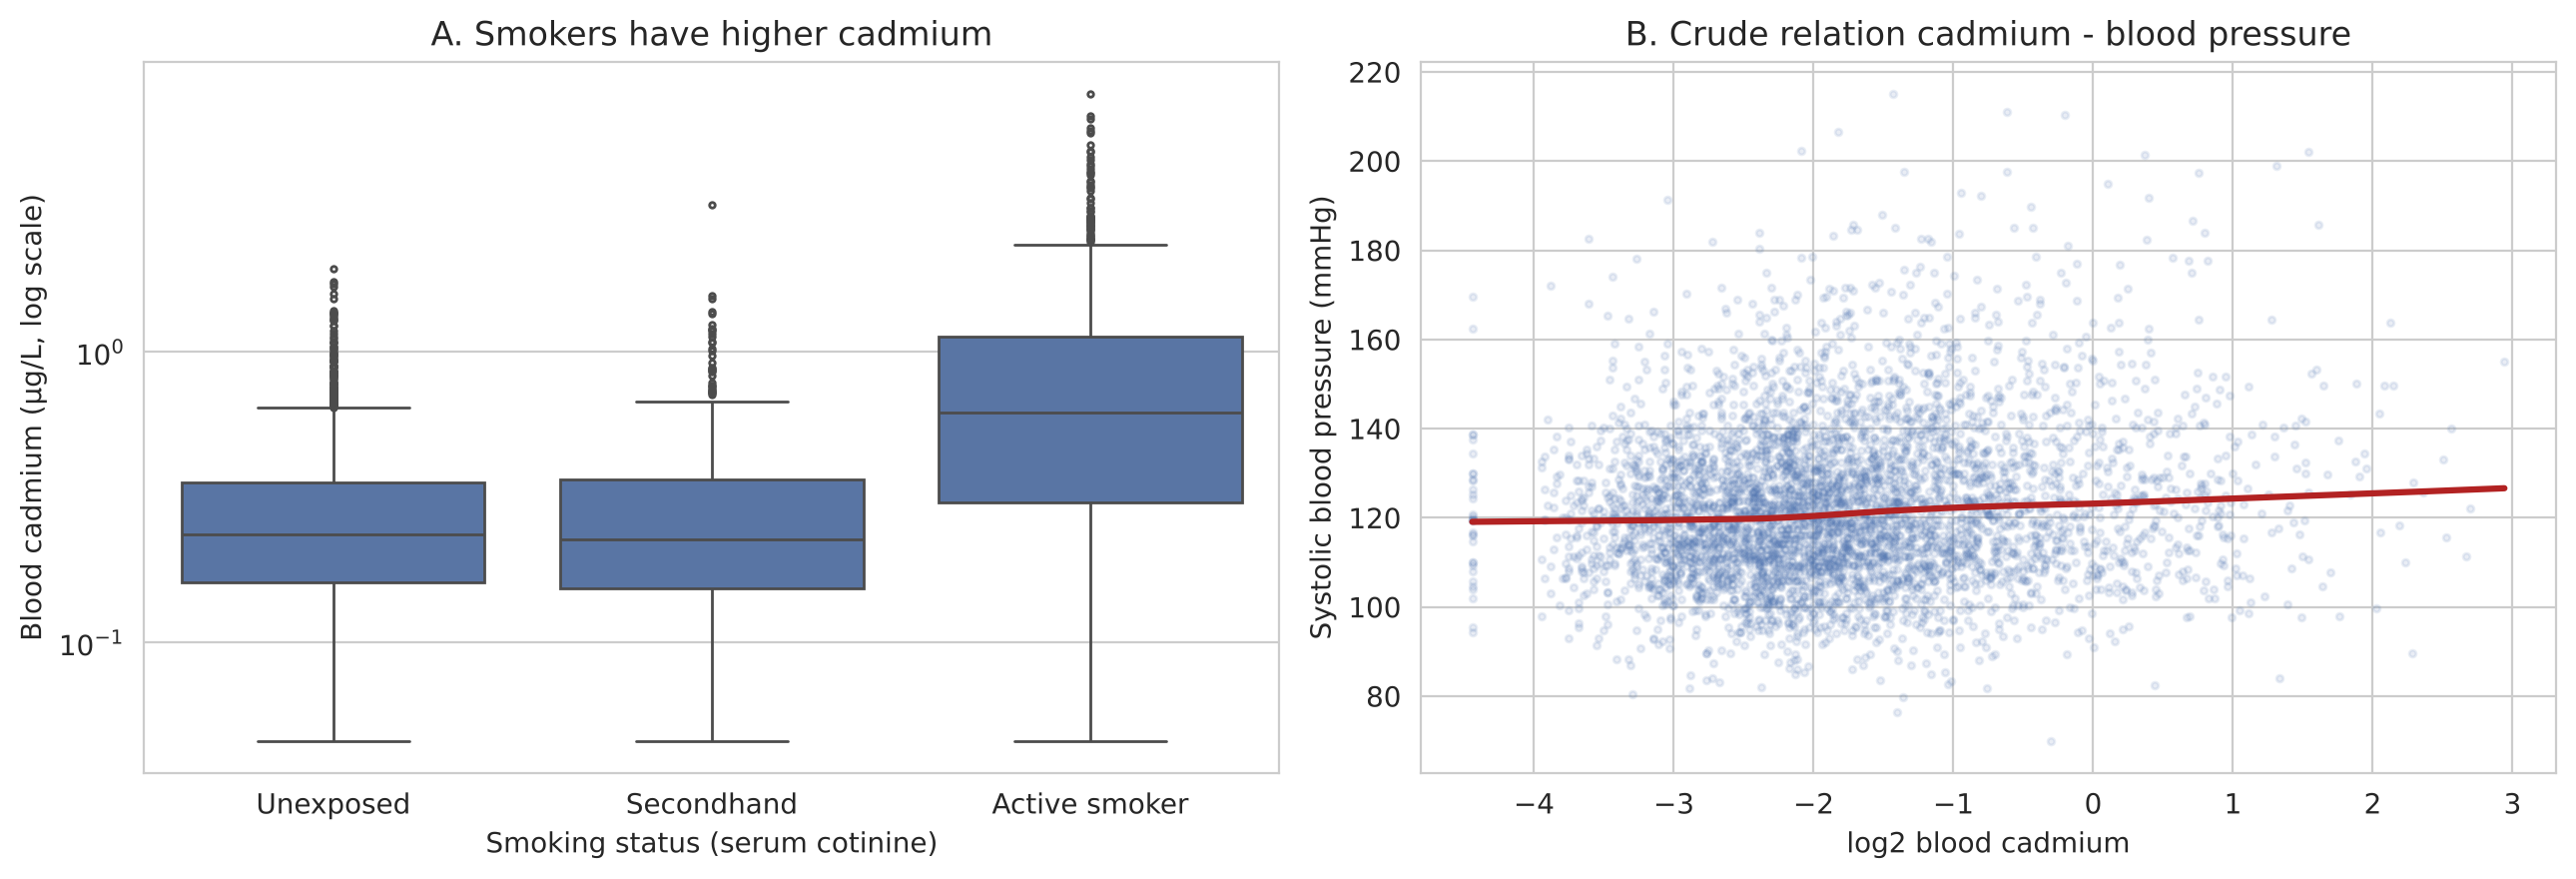

In [16]:
fig, axes = plt.subplots(figsize=(13, 4.5), ncols=2)

sns.boxplot(data=complete_data, x="smoking", y="LBXBCD", ax=axes[0], fliersize=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Smoking status (serum cotinine)")
axes[0].set_ylabel("Blood cadmium (µg/L, log scale)")
axes[0].set_title("A. Smokers have higher cadmium")

sns.regplot(data=complete_data, x="log2_cd", y="systolic_bp", lowess=True, ax=axes[1],
            scatter_kws={"alpha": 0.12, "s": 6}, line_kws={"color": "firebrick"})
axes[1].set_xlabel("log2 blood cadmium")
axes[1].set_ylabel("Systolic blood pressure (mmHg)")
axes[1].set_title("B. Crude relation cadmium - blood pressure")

plt.tight_layout()
plt.savefig("part2_descriptive.png", dpi=300)
plt.show()

**Question:** How do the participants with the highest cadmium differ from those with the lowest? What does this mean for a crude comparison of blood pressure?

**Answer:** Participants in the highest cadmium tertile are older (58 vs 47 years), more often women (62% vs 40%) and much more often active smokers (48% vs 10%) than those in the lowest tertile. Their blood pressure is higher (125.5 vs 120.5 mmHg). But age and smoking also affect blood pressure, so a crude comparison mixes the effect of cadmium with the effects of age, sex and smoking: this is **confounding**. Panel A shows the link between smoking and cadmium; panel B shows a slight crude increase of blood pressure with cadmium.

### Why we do not split the data
In the template, the data were split into a training, validation and test set, because the goal was to estimate how well
a model **predicts** new people. Here, the goal is to **estimate and test** one coefficient. We use all participants to
estimate it as precisely as possible. The uncertainty is described by the confidence interval and the p-value, and we
check the reliability of the model with its assumptions and with sensitivity analyses (section 6), not with a test set.

## 3. Starting simple: a crude linear regression model
As in the template, we start with a simple model: blood pressure explained by cadmium only, without any adjustment.
We use the statsmodels `ols()` function with a **formula**: `"systolic_bp ~ log2_cd"` reads as "systolic blood pressure
explained by log2 cadmium". The `fit()` method estimates the coefficients.

To compare the models, we write a small helper function that extracts the cadmium coefficient, its 95% confidence
interval and p-value from a fitted model:

In [17]:
def coefficient(model, term="log2_cd", label=None):
    """Estimate, 95% confidence interval and p-value of one term of a fitted statsmodels model."""
    ci = model.conf_int().loc[term]
    return pd.Series({"n": int(model.nobs), "estimate": model.params[term],
                      "CI low": ci[0], "CI high": ci[1], "p-value": model.pvalues[term]}, name=label)

In [18]:
m0 = smf.ols("systolic_bp ~ log2_cd", data=complete_data).fit()
m0.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            systolic_bp   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     64.36
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           1.31e-15
Time:                        09:41:42   Log-Likelihood:                -19727.
No. Observations:                4603   AIC:                         3.946e+04
Df Residuals:                    4601   BIC:                         3.947e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    126.0086      0.480    262.579      0.000     125.068     126.949
log2_cd        1.8389      0.229      8.022      0.000       1.389       2.288
==============================================================================
Omnibus:                      562.332   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              939.953
Skew:                           0.836   Prob(JB):                    7.80e-205
Kurtosis:                       4.451   Cond. No.                         4.54
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Question:** How do you interpret the coefficient of log2_cd? Is it significant? Does this already answer our research question?

**Answer:** Every doubling of blood cadmium is associated with a 1.84 mmHg higher systolic blood pressure (95% CI 1.39 to 2.29; p < 0.001). This is significant, but it does **not** answer our research question yet: the model is not adjusted for confounders. Note also the low R² (0.014): cadmium alone explains very little of the variation in blood pressure. That is not a problem for a hypothesis test, whose goal is to estimate one association, not to predict blood pressure well.

## 4. Adjusting for confounders: multivariable models
To see how much of the crude association is due to confounding, we add the confounders **step by step**. Every
variable in a formula is adjusted for all other variables in that formula:

* **M0** crude: cadmium only
* **M1** + age and sex
* **M2** + smoking and BMI
* **M3** + income and ethnicity (**main model**)

All models use exactly the same participants, so that differences between the models come from the adjustment, and not
from a different sample.

In [19]:
formulas = {
    "M0 crude":               "systolic_bp ~ log2_cd",
    "M1 + age, sex":          "systolic_bp ~ log2_cd + RIDAGEYR + sex",
    "M2 + smoking, BMI":      "systolic_bp ~ log2_cd + RIDAGEYR + sex + smoking + BMXBMI",
    "M3 + income, ethnicity": "systolic_bp ~ log2_cd + RIDAGEYR + sex + smoking + BMXBMI + INDFMPIR + ethnicity",
}
models = {name: smf.ols(formula, data=complete_data).fit() for name, formula in formulas.items()}
m3 = models["M3 + income, ethnicity"]

adjustment_table = pd.DataFrame([coefficient(model, label=name) for name, model in models.items()])
adjustment_table.round(4)

,n,estimate,CI low,CI high,p-value
M0 crude,4603.0,1.8389,1.3895,2.2883,0.0000
"M1 + age, sex",4603.0,0.8760,0.4390,1.3130,0.0001
"M2 + smoking, BMI",4603.0,0.6464,0.1104,1.1824,0.0181
"M3 + income, ethnicity",4603.0,0.4334,-0.1102,0.9771,0.1181


**Question:** What happens to the cadmium coefficient when we adjust for more confounders? Which step changes it most?

**Answer:** The coefficient shrinks with every adjustment step: from 1.84 (crude) to 0.88 (+ age and sex), 0.65 (+ smoking and BMI) and 0.43 mmHg per doubling (+ income and ethnicity). The biggest change comes from **age and sex**, which halve the estimate. Most of the crude association is therefore confounding: people with more cadmium are older, and older people have a higher blood pressure. In the main model M3, the confidence interval (−0.11 to 0.98) includes 0.

### The main model in detail

In [20]:
m3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            systolic_bp   R-squared:                       0.162
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     74.10
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          1.94e-166
Time:                        09:41:42   Log-Likelihood:                -19351.
No. Observations:                4603   AIC:                         3.873e+04
Df Residuals:                    4590   BIC:                         3.881e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
==================================================================================================
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                        104.2616      1.884     55.339      0.000     100.568     107.955
sex[T.Female]                     -4.5033      0.509     -8.844      0.000      -5.502      -3.505
smoking[T.Secondhand]              0.2209      0.794      0.278      0.781      -1.335       1.777
smoking[T.Active smoker]           0.9613      0.740      1.299      0.194      -0.489       2.412
ethnicity[T.Other Hispanic]       -1.1363      1.220     -0.931      0.352      -3.528       1.255
ethnicity[T.NH White]             -1.3060      1.016     -1.285      0.199      -3.298       0.686
ethnicity[T.NH Black]              3.6445      1.210      3.011      0.003       1.271       6.018
ethnicity[T.NH Asian]              0.6217      1.433      0.434      0.664      -2.188       3.431
ethnicity[T.Other/Multiracial]    -0.6677      1.352     -0.494      0.621      -3.318       1.983
log2_cd                            0.4334      0.277      1.563      0.118      -0.110       0.977
RIDAGEYR                           0.3903      0.016     24.241      0.000       0.359       0.422
BMXBMI                             0.0765      0.035      2.193      0.028       0.008       0.145
INDFMPIR                          -0.4552      0.160     -2.837      0.005      -0.770      -0.141
==============================================================================
Omnibus:                      494.178   Durbin-Watson:                   2.020
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              970.339
Skew:                           0.695   Prob(JB):                    1.97e-211
Kurtosis:                       4.768   Cond. No.                         677.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

For categorical variables with more than two categories (smoking, ethnicity), the summary gives one coefficient per
category. To get **one test per variable**, we use a type II analysis of variance with the `anova_lm()` function:

In [21]:
sm.stats.anova_lm(m3, typ=2).round(4)

,sum_sq,df,F,PR(>F)
sex,2.059041e+04,1.0,78.2125,0.0000
smoking,4.449168e+02,2.0,0.8450,0.4296
ethnicity,1.017137e+04,5.0,7.7272,0.0000
log2_cd,6.431238e+02,1.0,2.4429,0.1181
RIDAGEYR,1.547059e+05,1.0,587.6491,0.0000
BMXBMI,1.265633e+03,1.0,4.8075,0.0284
INDFMPIR,2.119197e+03,1.0,8.0498,0.0046
Residual,1.208374e+06,4590.0,NaN,NaN


**Question:** Interpret the coefficients of age, sex and income in the main model. Which variables are significantly associated with blood pressure?

**Answer:** **Age** is by far the strongest predictor: +0.39 mmHg per year (p < 0.001). **Women** have a 4.5 mmHg lower blood pressure than men at equal values of the other variables (p < 0.001). A higher **income** ratio goes with a slightly lower blood pressure (−0.46 mmHg per unit; p = 0.005). **BMI** (+0.08 mmHg per kg/m²; p = 0.03) and **ethnicity** (type II test p < 0.001; non-Hispanic Black participants +3.6 mmHg versus the reference group) are also significant. Smoking status is not significant after adjustment (p = 0.43). The model explains 16% of the variance in blood pressure (R² = 0.16).

**Question:** Based on the main model, do we reject H0 for the main effect of cadmium?

**Answer:** No. In the main model, every doubling of blood cadmium goes with a 0.43 mmHg higher blood pressure, but the 95% confidence interval (−0.11 to 0.98) includes 0 and p = 0.12 > 0.05. We **do not reject H0** for the main effect: after adjustment for the confounders, there is no significant association between cadmium and blood pressure in men and women together.

## 5. Effect modification: does the association differ between men and women?
An **interaction** term lets the effect of cadmium differ between men and women. In a formula, `log2_cd * sex` is
shorthand for `log2_cd + sex + log2_cd:sex`. The coefficient of `log2_cd:sex[T.Female]` is the **difference in slope**
between women and men.

In [22]:
m4 = smf.ols("systolic_bp ~ log2_cd * sex + RIDAGEYR + smoking + BMXBMI + INDFMPIR + ethnicity",
             data=complete_data).fit()
coefficient(m4, "log2_cd:sex[T.Female]", "interaction (women - men)").round(4)

n           4603.0000
estimate       1.4789
CI low         0.6344
CI high        2.3235
p-value        0.0006
Name: interaction (women - men), dtype: float64

M4 is M3 with one extra term. We compare both models with an F-test, using the `anova_lm()` function with two models:

In [23]:
sm.stats.anova_lm(m3, m4).round(4)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,4590.0,1.208374e+06,0.0,NaN,NaN,NaN
1,4589.0,1.205279e+06,1.0,3095.3536,11.7853,0.0006


The coefficient of `log2_cd` in M4 is the slope in **men** (the reference category). The slope in **women** is the sum
`log2_cd + log2_cd:sex[T.Female]`. The `t_test()` method gives its estimate, confidence interval and p-value:

In [24]:
slope_men = m4.t_test("log2_cd = 0")
slope_women = m4.t_test("log2_cd + log2_cd:sex[T.Female] = 0")

slopes = pd.DataFrame({
    "estimate": [slope_men.effect[0], slope_women.effect[0]],
    "CI low": [slope_men.conf_int()[0, 0], slope_women.conf_int()[0, 0]],
    "CI high": [slope_men.conf_int()[0, 1], slope_women.conf_int()[0, 1]],
    "p-value": [float(slope_men.pvalue), float(slope_women.pvalue)],
}, index=["Men", "Women"])
slopes.round(4)

,estimate,CI low,CI high,p-value
Men,-0.3315,-1.0284,0.3654,0.3511
Women,1.1474,0.4684,1.8265,0.0009


**Question:** Does the association between cadmium and blood pressure differ between men and women? Do we reject H0 for the interaction? How can the main effect be non-significant while the interaction is significant?

**Answer:** Yes. The interaction coefficient is 1.48 mmHg (95% CI 0.63 to 2.32) and the F-test comparing M3 and M4 gives p < 0.001 (F = 11.8, p = 0.0006). We **reject H0 for the interaction**. In **women**, every doubling of cadmium goes with a 1.15 mmHg higher blood pressure (95% CI 0.47 to 1.83; p < 0.001). In **men**, there is no association (−0.33 mmHg; 95% CI −1.03 to 0.37; p = 0.35). The main model M3 estimates one average slope for men and women together: a positive slope in women and a flat slope in men average out to a small, non-significant value. This matches the meta-analysis of Gallagher & Meliker (2010).

## 6. Checking the model

### Model assumptions
Linear regression assumes (1) a linear relation between the predictors and the outcome, (2) independent observations,
(3) normally distributed residuals, (4) a constant variance of the residuals, and (5) no strong correlation between the
predictors (multicollinearity). We also check for **influential observations**: single participants that change the
model a lot. **Cook's distance** measures this; a common rule of thumb flags values above 4/n.

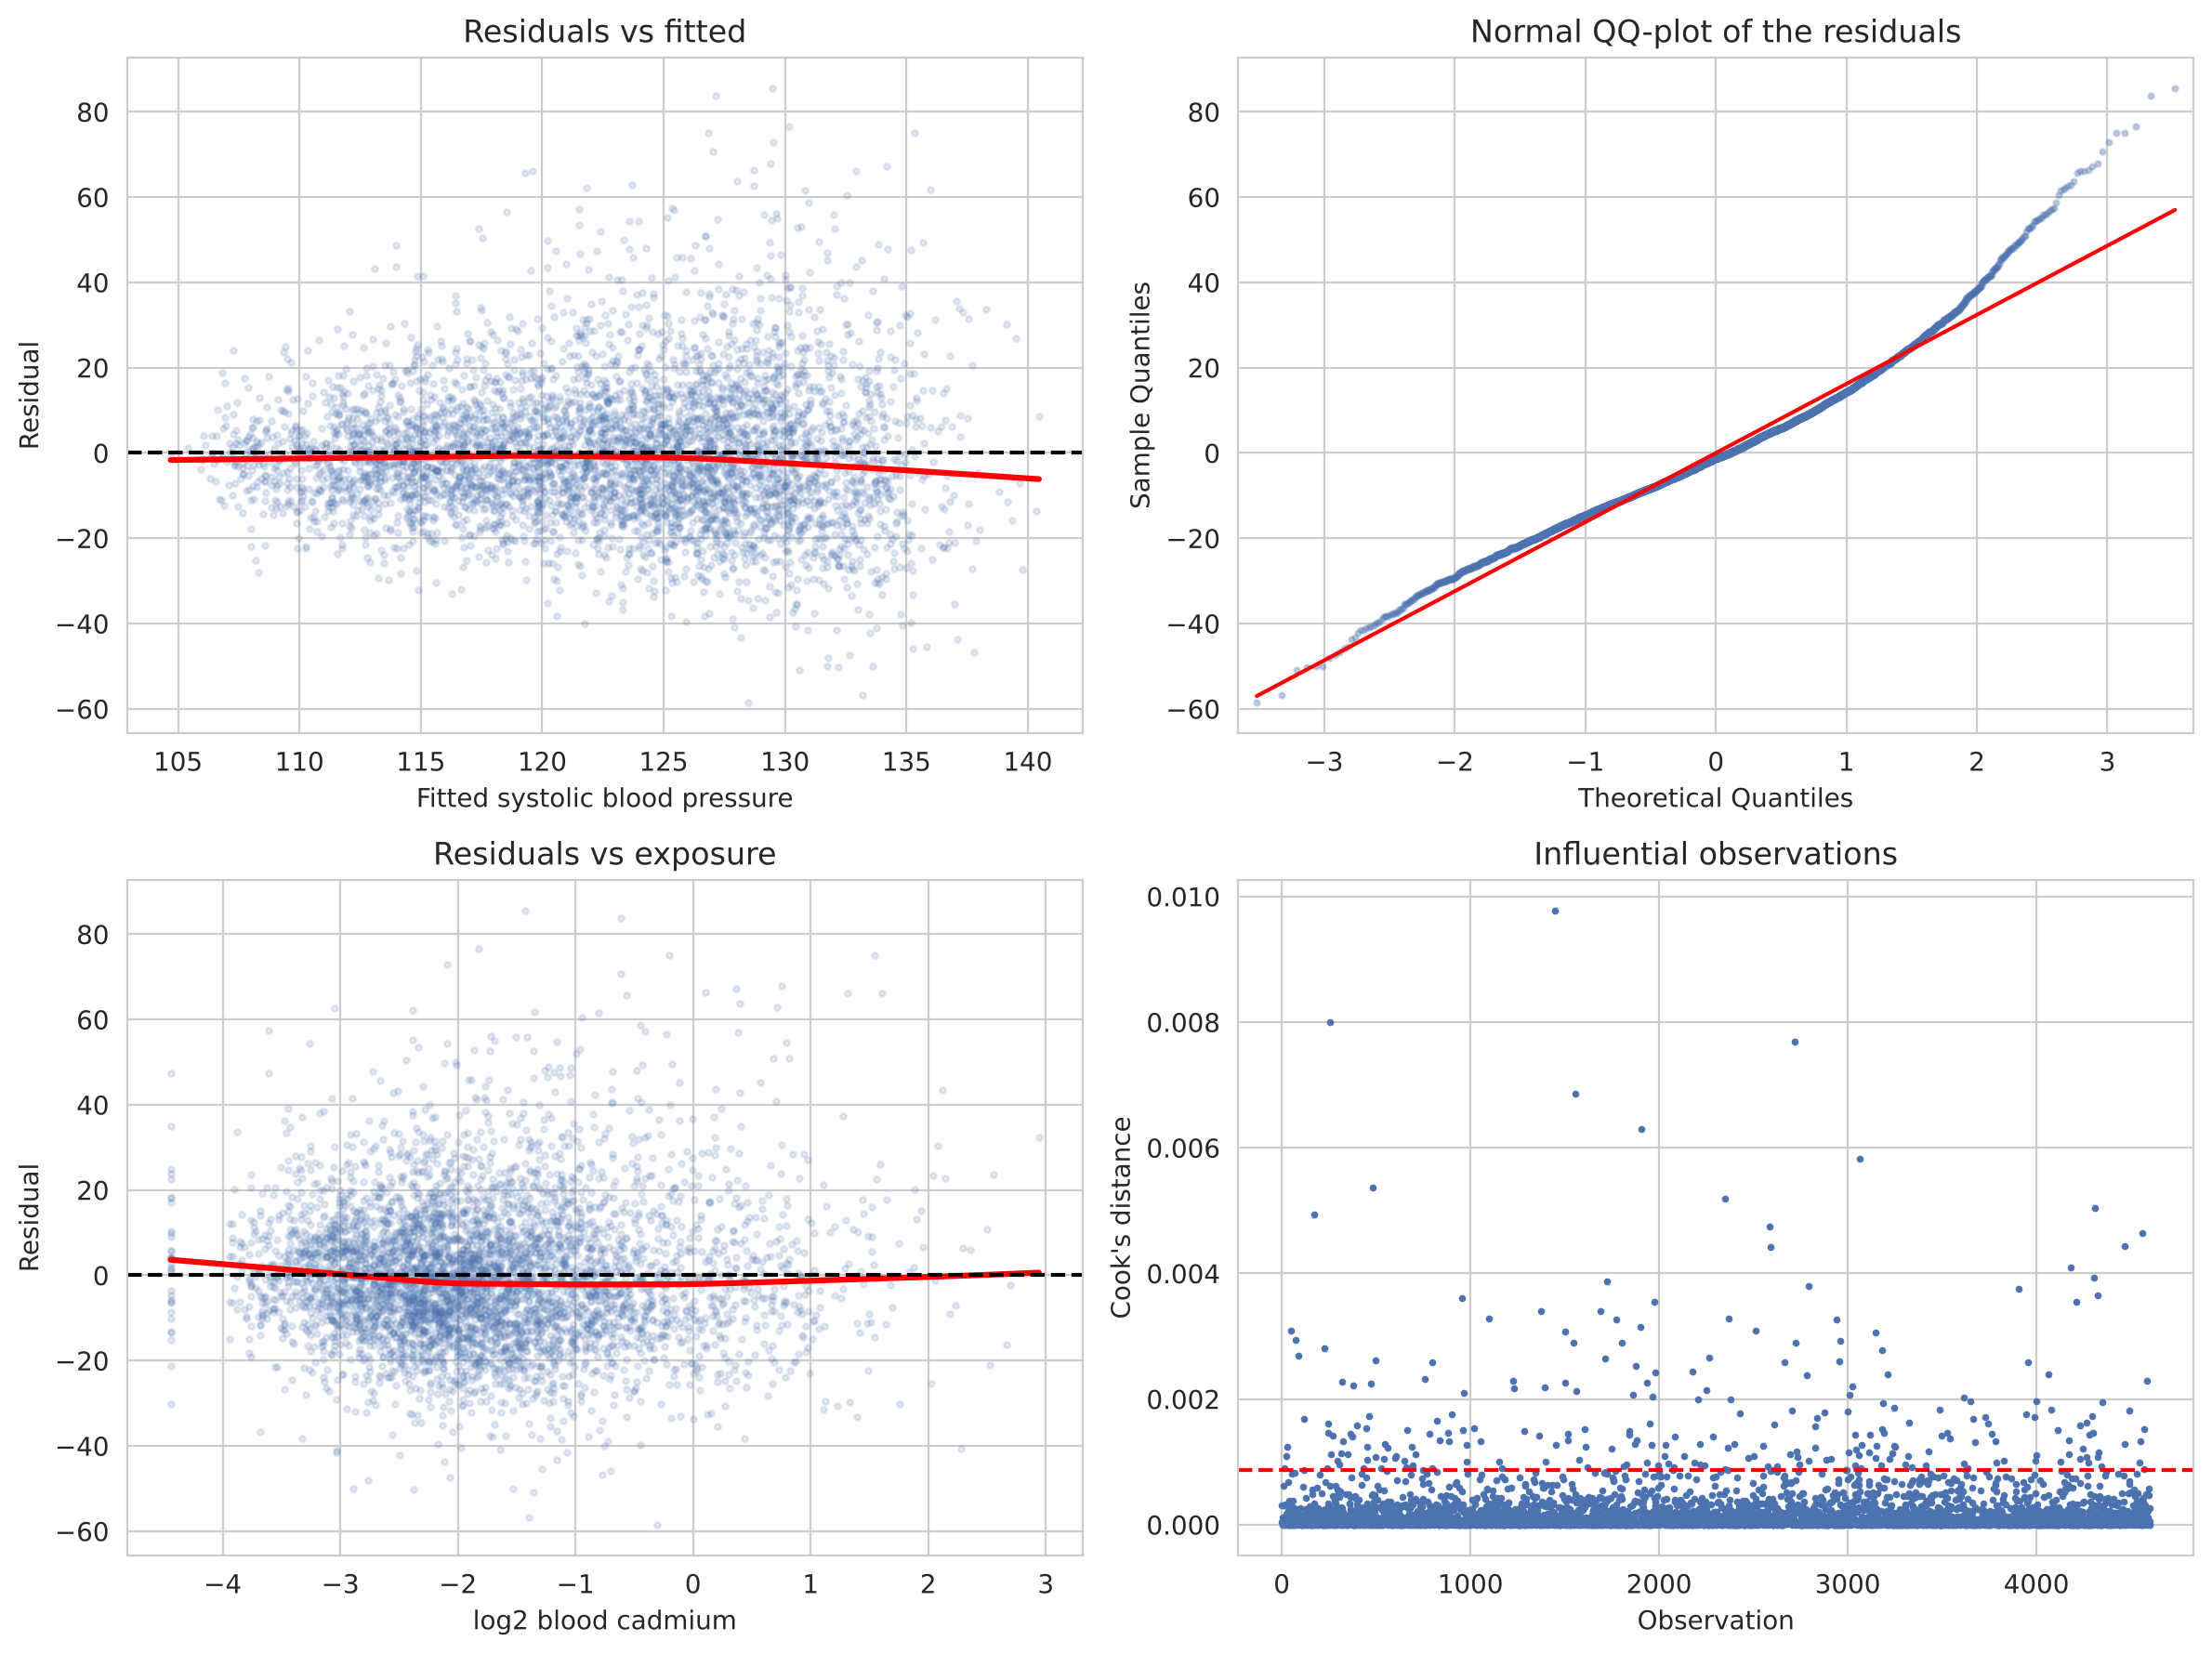

Observations with Cook's distance > 4/n: 255


In [25]:
residuals = m3.resid
fitted = m3.fittedvalues
cooks_distance = m3.get_influence().cooks_distance[0]

fig, axes = plt.subplots(figsize=(12, 9), ncols=2, nrows=2)

sns.regplot(x=fitted, y=residuals, lowess=True, ax=axes[0, 0],
            scatter_kws={"alpha": 0.15, "s": 5}, line_kws={"color": "red"})
axes[0, 0].axhline(0, color="black", linestyle="--")
axes[0, 0].set(xlabel="Fitted systolic blood pressure", ylabel="Residual", title="Residuals vs fitted")

sm.qqplot(residuals, line="s", ax=axes[0, 1], alpha=0.3, markersize=2)
axes[0, 1].set_title("Normal QQ-plot of the residuals")

sns.regplot(x=complete_data["log2_cd"], y=residuals, lowess=True, ax=axes[1, 0],
            scatter_kws={"alpha": 0.15, "s": 5}, line_kws={"color": "red"})
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(xlabel="log2 blood cadmium", ylabel="Residual", title="Residuals vs exposure")

axes[1, 1].scatter(range(len(cooks_distance)), cooks_distance, s=3)
axes[1, 1].axhline(4 / len(cooks_distance), color="red", linestyle="--")
axes[1, 1].set(xlabel="Observation", ylabel="Cook's distance", title="Influential observations")

plt.tight_layout()
plt.show()

print(f"Observations with Cook's distance > 4/n: {(cooks_distance > 4 / len(cooks_distance)).sum()}")

**Question:** What do the four plots tell you about the assumptions?

**Answer:** **Residuals vs fitted:** the points lie around 0 without a clear pattern, but the spread increases somewhat for higher fitted values (non-constant variance). **QQ-plot:** the residuals deviate from the line in the right tail: some participants have a much higher blood pressure than predicted. With 4,603 participants, the coefficients and confidence intervals are still reliable (central limit theorem). **Residuals vs exposure:** the line stays close to 0, with a slight curve at the extremes. **Cook's distance:** 255 observations lie above 4/n, but none stands out far above the rest. We check the effect of the variance, the skewness and the influential points in the sensitivity analyses.

**Linearity.** We test whether a flexible curve fits better than a straight line. The `cr()` function in a formula
replaces a variable by a natural cubic spline (here with 3 degrees of freedom; `constraints='center'` keeps the spline
from overlapping with the intercept). An F-test compares both models:

In [26]:
m3_spline_cd = smf.ols("systolic_bp ~ cr(log2_cd, df=3, constraints='center') + RIDAGEYR + sex + smoking + BMXBMI + INDFMPIR + ethnicity",
                       data=complete_data).fit()
m3_spline_age = smf.ols("systolic_bp ~ log2_cd + cr(RIDAGEYR, df=3, constraints='center') + sex + smoking + BMXBMI + INDFMPIR + ethnicity",
                        data=complete_data).fit()

print("Linearity of cadmium:")
print(sm.stats.anova_lm(m3, m3_spline_cd).round(4))
print()
print("Linearity of age:")
print(sm.stats.anova_lm(m3, m3_spline_age).round(4))

Linearity of cadmium:
   df_resid           ssr  df_diff    ss_diff        F  Pr(>F)
0    4590.0  1.208374e+06      0.0        NaN      NaN     NaN
1    4588.0  1.202881e+06      2.0  5493.2316  10.4761     0.0

Linearity of age:
   df_resid           ssr  df_diff   ss_diff       F  Pr(>F)
0    4590.0  1.208374e+06      0.0       NaN     NaN     NaN
1    4588.0  1.207642e+06      2.0  732.0541  1.3906   0.249


Let's look at the shape of the cadmium relation per sex, by comparing the predictions of the linear interaction model
(M4) with a spline version. The other variables are fixed at their average (age, BMI, income) or most common value:

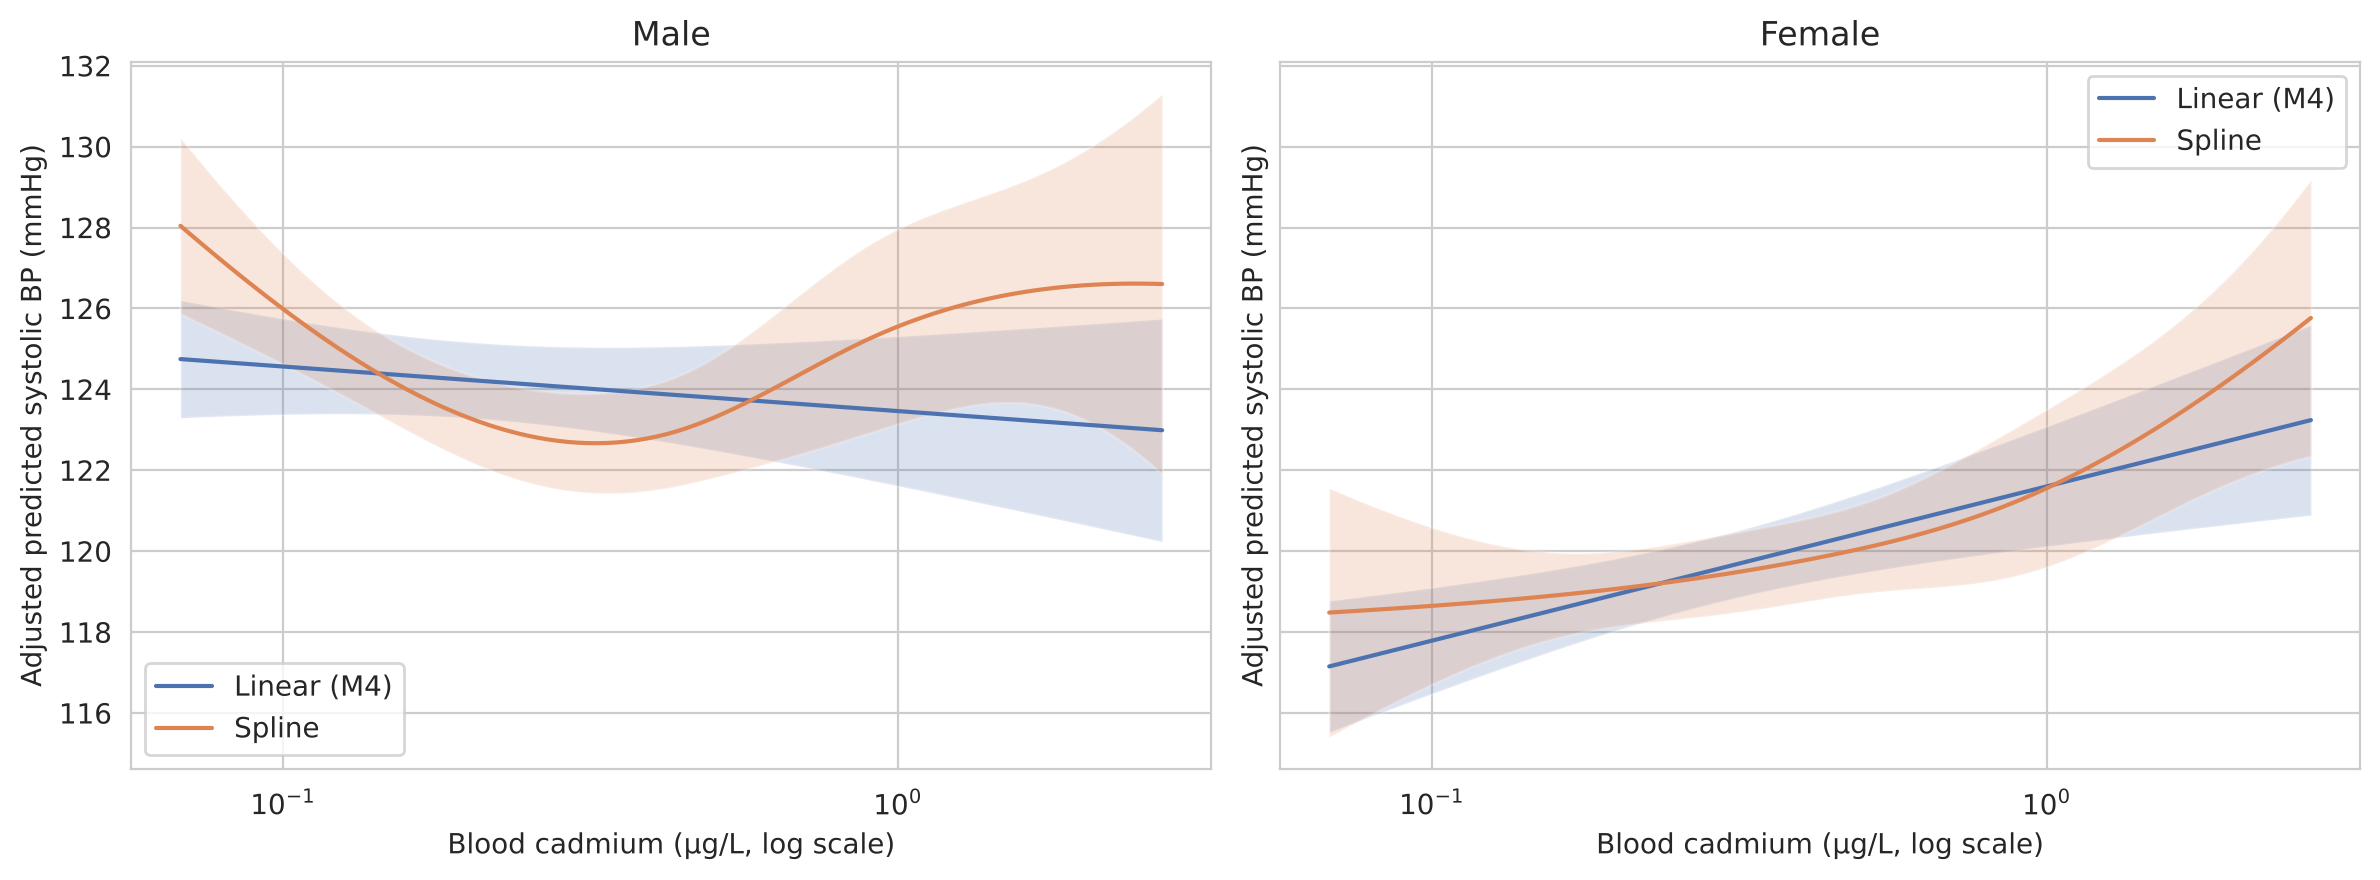

In [27]:
m4_spline = smf.ols("systolic_bp ~ cr(log2_cd, df=3, constraints='center') * sex + RIDAGEYR + smoking + BMXBMI + INDFMPIR + ethnicity",
                    data=complete_data).fit()

grid = pd.DataFrame([(x, s) for s in ["Male", "Female"]
                     for x in np.linspace(complete_data["log2_cd"].quantile(0.01),
                                          complete_data["log2_cd"].quantile(0.99), 100)],
                    columns=["log2_cd", "sex"])
grid = grid.assign(RIDAGEYR=complete_data["RIDAGEYR"].mean(), BMXBMI=complete_data["BMXBMI"].mean(),
                   INDFMPIR=complete_data["INDFMPIR"].mean(), smoking="Unexposed", ethnicity="NH White")
for column in ["sex", "smoking", "ethnicity"]:
    grid[column] = pd.Categorical(grid[column], categories=complete_data[column].cat.categories)

fig, axes = plt.subplots(figsize=(12, 4.5), ncols=2, sharey=True)
for ax, sex in zip(axes, ["Male", "Female"]):
    subset = grid[grid["sex"] == sex]
    for model, label in [(m4, "Linear (M4)"), (m4_spline, "Spline")]:
        prediction = model.get_prediction(subset).summary_frame()
        ax.plot(2 ** subset["log2_cd"], prediction["mean"], label=label)
        ax.fill_between(2 ** subset["log2_cd"], prediction["mean_ci_lower"], prediction["mean_ci_upper"], alpha=0.2)
    ax.set_xscale("log")
    ax.set(title=sex, xlabel="Blood cadmium (µg/L, log scale)", ylabel="Adjusted predicted systolic BP (mmHg)")
    ax.legend()
plt.tight_layout()
plt.show()

**Multicollinearity.** The variance inflation factor (VIF) measures how much the uncertainty of a coefficient increases
because the predictor is correlated with the other predictors. Values above 5 (or 10) indicate a problem. We compute it
with the `variance_inflation_factor()` function on the columns of the model's design matrix:

In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

design = pd.DataFrame(m3.model.exog, columns=m3.model.exog_names)
vif = pd.Series([variance_inflation_factor(design.values, i) for i in range(1, design.shape[1])],
                index=design.columns[1:], name="VIF")
vif.round(2)

sex[T.Female]                     1.12
smoking[T.Secondhand]             1.11
smoking[T.Active smoker]          1.73
ethnicity[T.Other Hispanic]       2.25
ethnicity[T.NH White]             4.27
ethnicity[T.NH Black]             2.41
ethnicity[T.NH Asian]             1.80
ethnicity[T.Other/Multiracial]    1.91
log2_cd                           1.72
RIDAGEYR                          1.27
BMXBMI                            1.07
INDFMPIR                          1.21
Name: VIF, dtype: float64

**Question:** Are the linearity and multicollinearity assumptions met?

**Answer:** **Age** is linear: the spline does not fit significantly better (p = 0.25). For **cadmium**, the spline fits significantly better (p < 0.001). With so many participants, even a small deviation from a straight line becomes significant. The figure shows that the deviation is mostly at the extremes, where there are few participants and the confidence bands are wide. In women, blood pressure increases over the whole range; in men, the curve has no clear direction. The linear coefficient is therefore a reasonable summary of the average trend, and we mention the deviation as a limitation. **Multicollinearity:** the VIF of cadmium is 1.7 and all continuous variables are below 2. The ethnicity indicators have higher values (up to 4.3 for NH White) because they are compared with the same, smaller reference group; this does not affect the cadmium coefficient, and all values are below 5.

### Sensitivity analyses
A sensitivity analysis repeats the analysis in a slightly different way. If the conclusion stays the same, it is
**robust**. Each analysis answers one specific doubt:

1. **Smoke-unexposed only** (cotinine < 0.05 ng/mL): is the association just residual confounding by smoking?
2. **log(systolic BP)** as the outcome: does the skewed outcome matter? (coefficient × 100 ≈ % change per doubling)
3. **Robust (HC3) standard errors**: does the non-constant variance matter?
4. **Without influential observations** (Cook's distance > 4/n): do a few participants drive the result?
5. **Spline for age**: does a non-linear age effect matter?
6. **Survey-weighted**: NHANES oversamples some groups and samples people in clusters. We use the exam weights
   (`WTMEC2YR`) and standard errors that allow for clustering within the sampling clusters (PSUs). This is an
   approximation of a full survey-design analysis: it gives the same estimates and very similar standard errors as the R
   `survey` package, but R computes p-values with far fewer degrees of freedom (see the answer below).
7. **Without cadmium values below the detection limit**: NHANES fills those in as LOD/√2.

In [29]:
covariates = "RIDAGEYR + sex + smoking + BMXBMI + INDFMPIR + ethnicity"
unexposed = complete_data[complete_data["smoking"] == "Unexposed"]
not_influential = complete_data[cooks_distance <= 4 / len(complete_data)]
above_lod = complete_data[complete_data["LBDBCDLC"] == 0]
cluster_id = complete_data["SDMVSTRA"] * 100 + complete_data["SDMVPSU"]

sensitivity = {
    "Main model (M3)": m3,
    "1. Smoke-unexposed only": smf.ols("systolic_bp ~ log2_cd + RIDAGEYR + sex + BMXBMI + INDFMPIR + ethnicity",
                                       data=unexposed).fit(),
    "2. log(systolic BP) [% change]": smf.ols(f"np.log(systolic_bp) ~ log2_cd + {covariates}", data=complete_data).fit(),
    "3. Robust (HC3) standard errors": smf.ols(f"systolic_bp ~ log2_cd + {covariates}", data=complete_data).fit(cov_type="HC3"),
    "4. Without influential observations": smf.ols(f"systolic_bp ~ log2_cd + {covariates}", data=not_influential).fit(),
    "5. Spline for age": m3_spline_age,
    "6. Survey-weighted (approximation)": smf.wls(f"systolic_bp ~ log2_cd + {covariates}", data=complete_data,
                                                  weights=complete_data["WTMEC2YR"]).fit(
                                                      cov_type="cluster", cov_kwds={"groups": cluster_id}),
    "7. Without values below the detection limit": smf.ols(f"systolic_bp ~ log2_cd + {covariates}", data=above_lod).fit(),
}
sensitivity_table = pd.DataFrame([coefficient(model, label=name) for name, model in sensitivity.items()])
sensitivity_table.loc["2. log(systolic BP) [% change]", ["estimate", "CI low", "CI high"]] *= 100
sensitivity_table.round(4)

,n,estimate,CI low,CI high,p-value
Main model (M3),4603.0,0.4334,-0.1102,0.9771,0.1181
1. Smoke-unexposed only,2991.0,-0.0057,-0.7876,0.7761,0.9885
2. log(systolic BP) [% change],4603.0,0.3057,-0.1221,0.7335,0.1612
3. Robust (HC3) standard errors,4603.0,0.4334,-0.1345,1.0014,0.1347
4. Without influential observations,4348.0,0.1269,-0.3391,0.5930,0.5934
5. Spline for age,4603.0,0.4758,-0.0702,1.0217,0.0877
6. Survey-weighted (approximation),4603.0,0.4790,-0.0791,1.0371,0.0925
7. Without values below the detection limit,4570.0,0.5046,-0.0514,1.0605,0.0752


Does the **interaction** with sex hold in the same analyses?

In [30]:
interaction_term = "log2_cd:sex[T.Female]"
interaction_covariates = "RIDAGEYR + smoking + BMXBMI + INDFMPIR + ethnicity"
m4_not_influential = complete_data[m4.get_influence().cooks_distance[0] <= 4 / len(complete_data)]

sensitivity_interaction = {
    "Main interaction model (M4)": m4,
    "1. Smoke-unexposed only": smf.ols("systolic_bp ~ log2_cd * sex + RIDAGEYR + BMXBMI + INDFMPIR + ethnicity",
                                       data=unexposed).fit(),
    "4. Without influential observations": smf.ols(f"systolic_bp ~ log2_cd * sex + {interaction_covariates}",
                                                   data=m4_not_influential).fit(),
    "6. Survey-weighted (approximation)": smf.wls(f"systolic_bp ~ log2_cd * sex + {interaction_covariates}",
                                                  data=complete_data, weights=complete_data["WTMEC2YR"]).fit(
                                                      cov_type="cluster", cov_kwds={"groups": cluster_id}),
    "7. Without values below the detection limit": smf.ols(f"systolic_bp ~ log2_cd * sex + {interaction_covariates}",
                                                           data=above_lod).fit(),
}
pd.DataFrame([coefficient(model, interaction_term, name) for name, model in sensitivity_interaction.items()]).round(4)

,n,estimate,CI low,CI high,p-value
Main interaction model (M4),4603.0,1.4789,0.6344,2.3235,0.0006
1. Smoke-unexposed only,2991.0,4.0231,2.6136,5.4327,0.0000
4. Without influential observations,4344.0,1.3924,0.6602,2.1247,0.0002
6. Survey-weighted (approximation),4603.0,2.2178,1.1979,3.2377,0.0000
7. Without values below the detection limit,4570.0,1.3499,0.4887,2.2112,0.0021


**Question:** Are the conclusions for the main effect and for the interaction robust?

**Answer:** **Main effect:** in none of the seven analyses is the cadmium coefficient significant (estimates between −0.01 and 0.50 mmHg per doubling, all p > 0.05). In participants without any tobacco smoke exposure, the estimate is practically 0 (−0.01). The conclusion "no overall association after adjustment" is robust. **Interaction:** the difference between women and men stays significant in all analyses, and is even larger in participants without tobacco smoke exposure (4.02 mmHg; p < 0.001). In that subgroup, the slope in men is negative, which should be interpreted with care: former smokers with high cadmium but low cotinine are also in that group. In the survey-weighted analysis, the interaction is larger (2.22 mmHg) with a similar standard error. Note: the full survey analysis in R (`survey` package) gives the same estimate and standard error (0.55), but computes the p-value with only 2 degrees of freedom: the design has only 15 degrees of freedom (30 sampling clusters in 15 strata), and the model uses almost all of them for its 14 parameters. This gives p = 0.056. That is very conservative; the direction and size of the interaction are the same.

### Results figure
Finally, we summarize the results in one figure: (A) the cadmium coefficient in each model and sensitivity analysis, and
(B) the adjusted predicted blood pressure by cadmium for men and women, from the interaction model M4.

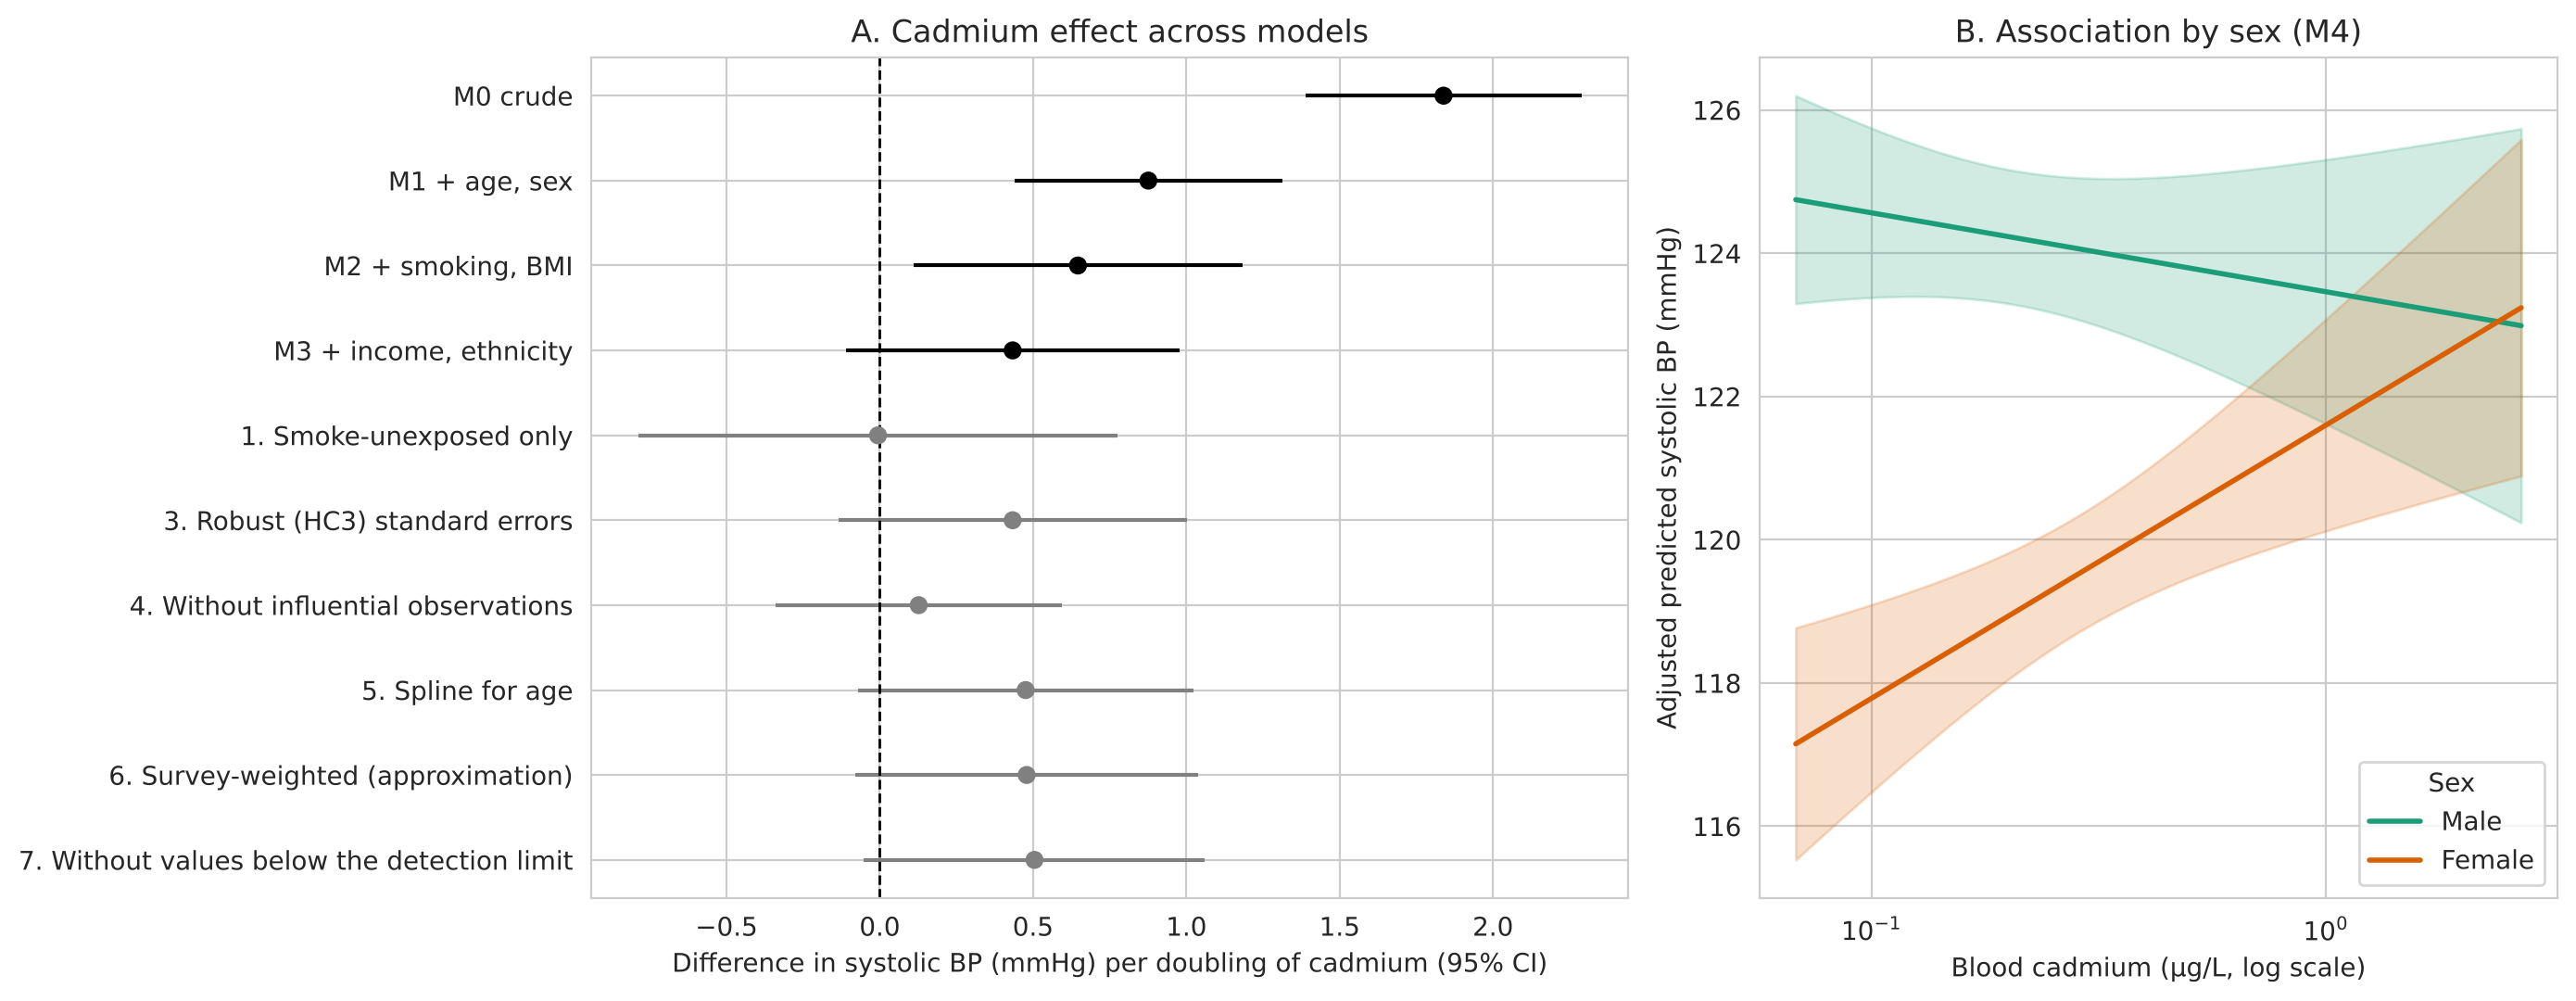

In [31]:
forest = pd.concat([adjustment_table.assign(group="Adjustment"),
                    sensitivity_table.drop(index=["Main model (M3)", "2. log(systolic BP) [% change]"])
                                     .assign(group="Sensitivity (vs M3)")])

fig, axes = plt.subplots(figsize=(14, 5.5), ncols=2, gridspec_kw={"width_ratios": [1.3, 1]})

y_positions = np.arange(len(forest))[::-1]
colors = forest["group"].map({"Adjustment": "black", "Sensitivity (vs M3)": "grey"})
axes[0].errorbar(forest["estimate"], y_positions,
                 xerr=[forest["estimate"] - forest["CI low"], forest["CI high"] - forest["estimate"]],
                 fmt="none", ecolor=colors, capsize=0)
axes[0].scatter(forest["estimate"], y_positions, c=colors, zorder=3)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_yticks(y_positions, forest.index)
axes[0].set_xlabel("Difference in systolic BP (mmHg) per doubling of cadmium (95% CI)")
axes[0].set_title("A. Cadmium effect across models")

palette = {"Male": "#1b9e77", "Female": "#d95f02"}
for sex in ["Male", "Female"]:
    subset = grid[grid["sex"] == sex]
    prediction = m4.get_prediction(subset).summary_frame()
    axes[1].plot(2 ** subset["log2_cd"], prediction["mean"], color=palette[sex], label=sex, linewidth=2)
    axes[1].fill_between(2 ** subset["log2_cd"], prediction["mean_ci_lower"], prediction["mean_ci_upper"],
                         color=palette[sex], alpha=0.2)
axes[1].set_xscale("log")
axes[1].set(xlabel="Blood cadmium (µg/L, log scale)", ylabel="Adjusted predicted systolic BP (mmHg)",
            title="B. Association by sex (M4)")
axes[1].legend(title="Sex")

plt.tight_layout()
plt.savefig("part2_results.png", dpi=300)
plt.show()

## 7. Conclusion

**Question:** How large is the effect in women? Is it relevant?

**Answer:** Going from the lowest to the highest cadmium tertile is about a 4-fold difference (median 0.14 to 0.61 µg/L), i.e. about 2 doublings. In women, that corresponds to about 2 × 1.15 ≈ **2.3 mmHg**, which equals about 6 years of ageing in this model (0.39 mmHg per year). For one person, this is small. At population level, however, small shifts in average blood pressure matter for cardiovascular risk.

**Question:** What is the answer to our research question?

**Answer:** After adjustment for age, sex, smoking, BMI, income and ethnicity, blood cadmium is **not** associated with systolic blood pressure in US adults overall (0.43 mmHg per doubling; 95% CI −0.11 to 0.98; p = 0.12). About half of the crude association disappears after adjustment for age and sex alone, so most of it is confounding. There is, however, a robust **sex-specific** association: in women, higher blood cadmium goes with a modestly higher systolic blood pressure (1.15 mmHg per doubling; p < 0.001), independent of smoking, while there is no association in men (interaction p < 0.001). This agrees with earlier studies (Gallagher & Meliker, 2010).

**Question:** What are the limitations of this analysis?

**Answer:** (1) **Cross-sectional design:** everything is measured at one moment, so we cannot conclude that cadmium causes a higher blood pressure. (2) **No information on blood pressure medication** in our dataset: treated participants have a lowered blood pressure, which probably weakens any association. (3) **Cotinine only reflects recent smoking** (days), while cadmium stays in the body for years: former smokers have high cadmium but are classified as unexposed. (4) **No adjustment for diet or kidney function.** (5) **Complete-case analysis:** participants without income information were removed, although they were similar to the included ones. (6) The relation between log2(cadmium) and blood pressure is **not perfectly linear**. (7) The main analysis is **unweighted** and describes our sample; the survey-weighted analysis gives the estimate for the US population. (8) We tested **two hypotheses**; the interaction remains significant after a Bonferroni correction (α = 0.025).

### References
* Gallagher CM, Meliker JR (2010). Blood and urine cadmium, blood pressure, and hypertension: a systematic review and
  meta-analysis. *Environmental Health Perspectives* 118(12):1676-1684.
* Benowitz NL et al. (2009). Optimal serum cotinine levels for distinguishing cigarette smokers and nonsmokers within
  different racial/ethnic groups in the United States between 1999 and 2004. *American Journal of Epidemiology*
  169(2):236-248.
* Homa DM et al. (2015). Vital Signs: Disparities in nonsmokers' exposure to secondhand smoke – United States,
  1999-2012. *MMWR* 64(4):103-108.
* CDC/NCHS. National Health and Nutrition Examination Survey 2021-2023.
  https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023